# ♻️ ReciclaIA · Entrenamiento del clasificador de residuos
### IA Generativa para la Gestión Industrial · Certamen I: app web con modelos preentrenados e IA generativa

**Integrantes:** Felipe Alonso · Sofía Fariña · Vicente Lagunas

**Problema:** separar mal los residuos contamina lotes completos de material reciclable. Queremos una app que, a partir de una foto, identifique el material y oriente sobre cómo y dónde reciclarlo.

**¿Para quién?** Personas y hogares que separan residuos en casa o en puntos limpios, en el contexto de la Ley REP (Ley 20.920), que exige aumentar el reciclaje de envases.
**Decisión que apoya:** en qué contenedor depositar cada residuo.
**Error más costoso:** clasificar basura no reciclable como reciclable, porque contamina el lote completo de reciclaje.

**Objetivo del notebook:** clasificar la foto de un residuo en 6 clases (cartón, vidrio, metal, papel, plástico y basura) con un modelo preentrenado, compararlo con otros enfoques usando la misma métrica y exportarlo para usarlo en la app.

**Flujo del proyecto:**
📷 Imagen → 🧠 Modelo preentrenado (clase + confianza) → 📊 Resultado visual → 💬 LLM → ✅ Recomendación

**Antes de empezar:** en Colab ve a *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4) ✅ *.

**Set adicional de fotos propias (prueba externa):** además de TrashNet, el grupo tomó fotos propias de residuos chilenos con iPhone, en fondos y luces reales. Estas fotos **no se usan para entrenar**: se usan solo al final, para comprobar si el modelo funciona con residuos reales fuera del dataset (sección de prueba externa).

## 0. Librerías

In [1]:
!pip install -q timm datasets transformers scikit-learn   # instala las librerías que Colab no trae

import shutil                                    # shutil: copiar y comprimir archivos (exportación)
from google.colab import files                   # files: descargar archivos de Colab a tu computador

# ---------- utilidades generales ----------
import os, json, random                          # os: rutas y carpetas · json: guardar clases y métricas · random: azar
import numpy as np                               # numpy: cálculo con matrices de números
import matplotlib.pyplot as plt                  # matplotlib: gráficos e imágenes

# ---------- deep learning (PyTorch) ----------
import torch, torch.nn as nn                     # torch: motor de deep learning · nn: capas y funciones de pérdida
from torch.utils.data import Dataset, DataLoader # Dataset/DataLoader: entregan las fotos al modelo por lotes
from torchvision import transforms               # transforms: redimensionar, normalizar y aumentar imágenes
import timm                                      # timm: modelos de visión preentrenados (EfficientNet, ResNet, ConvNeXt)

# ---------- datos (Hugging Face) ----------
from datasets import load_dataset                # load_dataset: lee imágenes organizadas en carpetas por clase
from huggingface_hub import hf_hub_download      # hf_hub_download: descarga archivos de un repositorio de Hugging Face
import zipfile                                   # zipfile: descomprime el dataset

# ---------- división de datos y métricas (scikit-learn) ----------
from sklearn.model_selection import train_test_split          # separa en entrenamiento, validación y prueba
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,   # accuracy normal y balanceada
                             confusion_matrix, ConfusionMatrixDisplay,  # matriz de confusión y su gráfico
                             classification_report,recall_score)                     # reporte por clase y recall por clase

import warnings; warnings.filterwarnings("ignore")             # oculta avisos que no afectan el resultado

# ---------- reproducibilidad ----------
SEMILLA = 2026                                   # semilla elegida
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"   # usa la GPU si está activa
print("Dispositivo:", DISPOSITIVO)

Dispositivo: cuda


## 1. Los datos

| Aspecto | Detalle |
|---|---|
| Dataset | **TrashNet** |
| Autores | Gary Thung y Mindy Yang (Universidad de Stanford, 2016) |
| Cómo se obtuvo | Fotos tomadas por los autores con iPhone, de un objeto a la vez sobre una cartulina blanca, con luz solar o de la habitación; redimensionadas a 512 × 384 px |
| Licencia | **MIT** (uso libre citando a los autores) |
| Copia usada | Hugging Face `garythung/trashnet`, archivo `dataset-resized.zip` |
| Clases | `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash` |

**Nota:** el repositorio de Hugging Face trae dos versiones de las **mismas** fotos (original y redimensionada). Usamos solo la redimensionada, porque si cargamos ambas cada foto aparecería dos veces y podría quedar una copia en entrenamiento y otra en prueba (*fuga de datos*).

**Referencia:** Yang, M. y Thung, G. (2016). *Classification of Trash for Recyclability Status*. Stanford CS229. https://huggingface.co/datasets/garythung/trashnet · https://github.com/garythung/trashnet

In [2]:
# descarga solo la versión redimensionada del dataset desde Hugging Face
zip_ruta = hf_hub_download("garythung/trashnet", "dataset-resized.zip", repo_type="dataset")

with zipfile.ZipFile(zip_ruta) as z:          # abre el archivo .zip
    z.extractall("trashnet")                  # lo descomprime en la carpeta "trashnet"

# busca la carpeta que contiene las 6 subcarpetas de clase
CLASES_ESPERADAS = {"cardboard", "glass", "metal", "paper", "plastic", "trash"}
RAIZ_DATOS = next(r for r, d, _ in os.walk("trashnet")
                  if "__MACOSX" not in r and CLASES_ESPERADAS <= set(d))
print("Carpeta de datos:", RAIZ_DATOS)

ds = load_dataset("imagefolder", data_dir=RAIZ_DATOS, split="train")   # el nombre de cada carpeta es la etiqueta
NOMBRES = ds.features["label"].names          # nombres de las clases en orden alfabético
print(ds)
print("Clases:", NOMBRES)

Carpeta de datos: trashnet/dataset-resized


Resolving data files:   0%|          | 0/2527 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image', 'label'],
    num_rows: 2527
})
Clases: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


### 1.1 Imágenes por clase y desbalance

cardboard :  403 imágenes (15.9%)
glass     :  501 imágenes (19.8%)
metal     :  410 imágenes (16.2%)
paper     :  594 imágenes (23.5%)
plastic   :  482 imágenes (19.1%)
trash     :  137 imágenes (5.4%)
Total: 2527
Razón entre la clase más grande y la más pequeña: 4.3


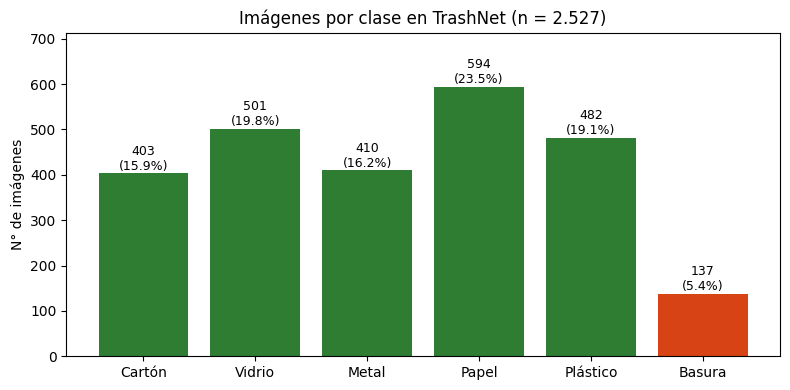

In [ ]:
etiquetas = np.array(ds["label"])                          # # etiqueta de cada una de las 2.527 fotos (número de 0 a 5 según la clase)
conteo = np.bincount(etiquetas, minlength=len(NOMBRES))    # cuántas veces aparece cada numero

for nombre, cantidad in zip(NOMBRES, conteo):              # Recorre las 6 clases e imprime su nombre, su cantidad y su porcentaje del total
    print(f"{nombre:10s}: {cantidad:4d} imágenes ({cantidad / conteo.sum():.1%})")
print("Total:", conteo.sum())
print("Razón entre la clase más grande y la más pequeña:", round(conteo.max() / conteo.min(), 1)) #Divide la clase más grande por la más pequeña

# nombres en español solo para el gráfico (el modelo sigue usando los nombres originales)
ES = {"cardboard": "Cartón", "glass": "Vidrio", "metal": "Metal",
      "paper": "Papel", "plastic": "Plástico", "trash": "Basura"}
etiquetas_es = [ES[n] for n in NOMBRES]

colores = ["#d84315" if n == "trash" else "#2e7d32" for n in NOMBRES]   # trash en naranjo, el resto en verde

plt.figure(figsize=(8, 4))
barras = plt.bar(etiquetas_es, conteo, color=colores)
for barra, cantidad in zip(barras, conteo):              # escribe cantidad y % encima de cada barra
    plt.text(barra.get_x() + barra.get_width() / 2, cantidad + 8,
             f"{cantidad}\n({cantidad / conteo.sum():.1%})", ha="center", fontsize=9)
plt.title("Imágenes por clase en TrashNet (n = 2.527)")
plt.ylabel("N° de imágenes"); plt.ylim(0, conteo.max() * 1.2)  # deja espacio arriba para los textos
plt.tight_layout(); plt.show()

**Análisis del desbalance**

El dataset tiene **2.527 imágenes** en 6 clases. Cinco clases están relativamente equilibradas, entre 15,9 % (cartón) y 23,5 % (papel). En cambio, la clase **basura no reciclable (`trash`) tiene solo 137 imágenes (5,4 %)**: hay **4,3 veces más fotos de papel que de basura**.

**¿Por qué importa?** `trash` es la clase más crítica para el problema, porque clasificar un residuo no reciclable como reciclable contamina el lote completo (nuestro error más costoso). Al tener tan pocos ejemplos, el modelo aprenderá menos de esta clase y podría equivocarse justamente ahí. Además, como es solo el 5 % de los datos, fallar en ella casi no bajaría la accuracy total: **la accuracy por sí sola puede engañar**.

**Decisiones que tomamos a partir de este análisis:**
1. **División estratificada** en entrenamiento, validación y prueba, para mantener la misma proporción de cada clase en los tres conjuntos.
2. **Evaluación con accuracy balanceada y recall por clase**, además de la accuracy, para que el desempeño en `trash` pese lo mismo que el de las otras clases.
3. **Entrenamiento con pérdida ponderada por clase**, que da más peso a los errores en `trash` para compensar que tiene menos ejemplos.

### 1.2 Revisión de duplicados
Si una misma foto aparece dos veces, podría quedar una copia en entrenamiento y otra en prueba (*fuga de datos*): el modelo la acertaría por memoria y las métricas saldrían infladas. Para evitarlo, calculamos una huella digital (*hash*) de cada imagen y eliminamos las copias exactas.

In [4]:
import hashlib                                            # hashlib: calcula huellas digitales (hash)

huellas = {}                                              # guarda cada huella ya vista y en qué foto apareció
duplicados = []                                           # aquí anotamos las fotos repetidas
for i, img in enumerate(ds["image"]):                     # recorre las 2.527 fotos una por una
    huella = hashlib.md5(img.tobytes()).hexdigest()       # Convierte todos los píxeles de la foto en un código corto
    if huella in huellas:                                 # si esa huella ya existía, la foto es una copia
        duplicados.append(i)
    else:
        huellas[huella] = i                               # si es nueva, la guardamos

print("Fotos duplicadas encontradas:", len(duplicados))
for i in duplicados:                                      # muestra de qué clase es cada copia
    print(f" - foto {i}: clase {NOMBRES[etiquetas[i]]}")

a_eliminar = set(duplicados)                              # conjunto de fotos a sacar
ds = ds.select([i for i in range(len(ds)) if i not in a_eliminar])   # dataset nuevo, sin las copias
etiquetas = np.array(ds["label"])                         # actualiza las etiquetas después de limpiar
print("Imágenes después de limpiar:", len(ds))

Fotos duplicadas encontradas: 3
 - foto 1305: clase metal
 - foto 1967: clase plastic
 - foto 2167: clase plastic
Imágenes después de limpiar: 2524


**Resultado:** se encontraron **3 imágenes duplicadas** (1 de `metal` y 2 de `plastic`), que se eliminaron. El dataset queda con **2.524 imágenes**. La clase `trash` no tenía duplicados, por lo que el análisis de desbalance no cambia.

**Limitación:** este método solo detecta copias exactas (mismos píxeles). Podrían existir fotos casi iguales del mismo objeto (por ejemplo, con un ángulo apenas distinto) que no se detectan; esto se considera en las limitaciones del dataset.

## 2. División en entrenamiento, validación y prueba

| Conjunto | % | Uso |
|---|---|---|
| Entrenamiento | 70 % | El modelo aprende con estas imágenes |
| Validación | 15 % | Revisar el entrenamiento y tomar decisiones (épocas, umbral de confianza) |
| Prueba | 15 % | Medir el desempeño final **una sola vez**, con imágenes que el modelo nunca vio |

La división es **estratificada**: cada conjunto mantiene la misma proporción de cada clase que el dataset completo. Esto es importante porque `trash` es solo el 5,4 % de los datos: sin estratificar, podría quedar con muy pocas imágenes en prueba. Se usa la semilla fija SEMILLA = 2026 para que la división sea reproducible.

In [5]:
indices = np.arange(len(ds))                              # número de cada foto: 0, 1, 2, ..., 2523

# 1° corte: 70 % entrenamiento y 30 % restante (estratificado por clase)
idx_train, idx_resto = train_test_split(
    indices, test_size=0.30,
    stratify=etiquetas, #Hace que cada parte mantenga la proporción de cada clase
    random_state=SEMILLA)

# 2° corte: el 30 % restante se divide en partes iguales -> 15 % validación y 15 % prueba
idx_val, idx_test = train_test_split(
    idx_resto, test_size=0.50, stratify=etiquetas[idx_resto], random_state=SEMILLA)

# comprobación: ninguna foto puede estar en dos conjuntos a la vez
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test)) #Comprueba que ninguna foto quedó repetida en dos conjuntos

# tabla con cuántas fotos de cada clase quedaron en cada conjunto
print(f"{'Clase':10s} {'Train':>6s} {'Val':>5s} {'Test':>5s}")
for c, nombre in enumerate(NOMBRES):
    print(f"{nombre:10s} {np.sum(etiquetas[idx_train] == c):6d} "
          f"{np.sum(etiquetas[idx_val] == c):5d} {np.sum(etiquetas[idx_test] == c):5d}")
print(f"{'TOTAL':10s} {len(idx_train):6d} {len(idx_val):5d} {len(idx_test):5d}")

Clase       Train   Val  Test
cardboard     282    60    61
glass         350    75    76
metal         286    62    61
paper         416    89    89
plastic       336    72    72
trash          96    21    20
TOTAL        1766   379   379


**Resultado de la división:** 1.766 imágenes de entrenamiento (70 %), 379 de validación (15 %) y 379 de prueba (15 %). Gracias a la estratificación, todas las clases mantienen su proporción en los tres conjuntos; la clase `trash` queda con 96 / 21 / 20 imágenes. La comprobación con `assert` confirma que ninguna imagen está en más de un conjunto.

**Ojo al interpretar:** la prueba tiene solo 20 imágenes de `trash`, por lo que cada error en esa clase cambia su recall en 5 puntos porcentuales. Sus métricas tendrán más variación que las de las otras clases.

### 2.1 Limitaciones de los datos

| Limitación | Cómo afecta | Qué hacemos |
|---|---|---|
| **Desbalance:** `trash` tiene solo 137 imágenes (5,4 %) y 20 en prueba | El modelo aprende menos de la clase más crítica, y su recall en prueba cambia 5 puntos por cada error | Estratificación, accuracy balanceada, recall por clase y pérdida ponderada |
| **Condiciones controladas:** cada objeto se fotografió solo, sobre una cartulina blanca, con luz solar o de la habitación | Con fondos reales (cocina, calle) o varios objetos en la foto, el modelo puede fallar más | Prueba externa con fotos propias; revisión humana si la confianza es baja |
| **Una sola fuente:** las fotos las tomaron los dos autores en 2016 | Los residuos pueden no representar los envases que se usan hoy en Chile | Prueba externa con residuos chilenos |
| **Posibles fotos casi iguales:** se eliminaron 3 copias exactas, pero podría haber fotos muy parecidas del mismo objeto | Las métricas podrían salir algo infladas | Se declara como riesgo y se contrasta con la prueba externa |

## 3. Línea base: CLIP sin entrenar (zero-shot)

**CLIP** (OpenAI, 2021) se entrenó con 400 millones de pares imagen–texto de internet. Puede clasificar una imagen **sin entrenar con nuestros datos**: le damos una descripción en texto de cada clase y elige la más parecida a la imagen (*zero-shot*).

**¿Por qué como línea base?** Responde si basta un modelo general ya hecho o si se justifica entrenar uno propio (*build vs. buy*). Todos los modelos se evalúan con **las mismas 379 imágenes de prueba** y las mismas métricas: **accuracy** y **accuracy balanceada** (promedio del acierto por clase, para que `trash` pese igual que las demás). Con 6 clases, el azar sería 16,7 %.

In [6]:
from transformers import pipeline                          # pipeline: usa un modelo de Hugging Face en pocas líneas

GPU = 0 if DISPOSITIVO == "cuda" else -1                   # 0 = usar la GPU, -1 = usar CPU
clip = pipeline("zero-shot-image-classification",          # tarea: clasificar imágenes sin entrenar. Carga CLIP listo para usar
                model="openai/clip-vit-base-patch32", device=GPU)

# una descripción en inglés por clase (CLIP aprendió con textos en inglés)
TEXTOS = { #No hay entrenamiento: CLIP solo compara la foto con estas frases
    "cardboard": "a photo of cardboard or a cardboard box",
    "glass":     "a photo of a glass bottle or glass jar",
    "metal":     "a photo of a metal can or metal object",
    "paper":     "a photo of paper, a sheet of paper or newspaper",
    "plastic":   "a photo of a plastic bottle or plastic container",
    "trash":     "a photo of non-recyclable trash such as a food wrapper",
}
A_CLASE = {texto: clase for clase, texto in TEXTOS.items()}   # para traducir la frase elegida a su clase

reales, preds_clip = [], []
for i in idx_test:                                         # recorre las 379 imágenes de prueba
    foto = ds[int(i)]
    respuesta = clip(foto["image"], candidate_labels=list(TEXTOS.values()))   # CLIP ordena las frases por parecido
    preds_clip.append(A_CLASE[respuesta[0]["label"]])      # la primera es la más parecida = su predicción
    reales.append(NOMBRES[foto["label"]])                  # la clase verdadera

RESULTADOS = {}                                            # aquí guardaremos los resultados de todos los modelos
RESULTADOS["CLIP (sin entrenar)"] = {
    "accuracy": accuracy_score(reales, preds_clip),
    "accuracy_balanceada": balanced_accuracy_score(reales, preds_clip), #La métrica que hace que trash pese igual que las demás clases
}
print(f"CLIP · accuracy = {RESULTADOS['CLIP (sin entrenar)']['accuracy']:.1%} · "
      f"accuracy balanceada = {RESULTADOS['CLIP (sin entrenar)']['accuracy_balanceada']:.1%}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


CLIP · accuracy = 60.2% · accuracy balanceada = 64.4%


In [7]:
print(classification_report(reales, preds_clip, labels=NOMBRES, digits=2))   # precision, recall y F1 de cada clase

              precision    recall  f1-score   support

   cardboard       0.86      0.72      0.79        61
       glass       0.85      0.43      0.57        76
       metal       0.78      0.66      0.71        61
       paper       0.97      0.43      0.59        89
     plastic       0.54      0.78      0.64        72
       trash       0.18      0.85      0.30        20

    accuracy                           0.60       379
   macro avg       0.70      0.64      0.60       379
weighted avg       0.78      0.60      0.63       379



**Resultado de la línea base:** CLIP sin entrenar obtiene **60,2 % de accuracy** y **64,4 % de accuracy balanceada** en las 379 imágenes de prueba, muy por encima del azar (16,7 %).

**¿Dónde se equivoca?** El reporte por clase muestra que CLIP **sobreetiqueta como basura** (`trash`): reconoce el 85 % de la basura real (recall 0,85), pero cuando dice "basura" solo acierta el 18 % de las veces (precision 0,18). Muchos residuos reciclables, sobre todo vidrio y papel (recall 0,43 en ambos), terminan clasificados como basura. Por eso su accuracy balanceada parece aceptable: acierta en `trash` porque predice esa clase con mucha frecuencia.

**Impacto en el problema:** este error no contamina el reciclaje, pero hace que **se pierda material reciclable** que iría a la basura. Una métrica sola no basta: hay que mirar precision y recall juntas.

**Conclusión (build vs. buy):** un modelo general sin adaptar no es suficiente para orientar el reciclaje, porque se equivoca en cerca de 4 de cada 10 imágenes. Esto justifica **entrenar un modelo propio con nuestros datos** mediante *transfer learning*.

## 4. Segundo enfoque: EfficientNet-B0 con transfer learning

**Transfer learning:** reutilizamos EfficientNet-B0 (librería `timm`), ya entrenada con ImageNet. Conservamos su *backbone* (las capas que ya saben detectar bordes, texturas y formas) y reemplazamos su cabeza por una nueva de **6 clases**. Luego la ajustamos con nuestras imágenes usando una tasa de aprendizaje pequeña, para no perder lo que ya sabe.

**¿Por qué EfficientNet-B0?** Es liviana (~4 M de parámetros con 6 clases, ~16 MB), precisa y rápida: cabe en GitHub y funciona en la app sin GPU.

### 4.1 Preparación de las imágenes
- **Entrenamiento:** redimensionar a 224×224 y aplicar **aumento de datos** (volteo, rotación y cambios de brillo/contraste al azar), para que el modelo aprenda el material y no la posición o la luz exacta.
- **Validación y prueba:** solo redimensionar y normalizar, sin alterar las imágenes, para evaluar de forma justa.
- **Normalización:** se usan los valores de ImageNet, los mismos con que se entrenó el modelo original.

In [8]:
TAM = 224                                                   # tamaño de entrada que espera EfficientNet-B0
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # valores de normalización de ImageNet

# transformaciones para ENTRENAR: incluyen aumento de datos (variaciones al azar)
tf_train = transforms.Compose([
    transforms.Resize((TAM, TAM)),                          # todas las fotos al mismo tamaño
    transforms.RandomHorizontalFlip(),                      # voltea la foto horizontalmente al azar
    transforms.RandomRotation(15),                          # la rota hasta ±15 grados
    transforms.ColorJitter(brightness=0.2, contrast=0.2),   # cambia un poco el brillo y el contraste
    transforms.ToTensor(),                                  # convierte la foto en números (tensor)
    transforms.Normalize(MEDIA, DESV),                      # normaliza los colores como en ImageNet
])

# transformaciones para VALIDAR y PROBAR: sin aumento de datos
tf_eval = transforms.Compose([
    transforms.Resize((TAM, TAM)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESV),
])
#tf_train /tf_eval: Dos “recetas” para preparar las fotos: con variaciones para entrenar y sin variaciones para evaluar
class Residuos(Dataset): #Le dice a PyTorch cómo sacar cada foto de un conjunto y prepararla
    def __init__(self, indices, transformacion):
        self.indices = [int(i) for i in indices]            # qué fotos del dataset pertenecen a este conjunto
        self.tf = transformacion
    def __len__(self):
        return len(self.indices)                            # cuántas fotos tiene el conjunto
    def __getitem__(self, k):
        foto = ds[self.indices[k]]                          # toma la foto número k del conjunto
        return self.tf(foto["image"].convert("RGB")), foto["label"]   # (imagen transformada, clase)

LOTE = 32                                                   # cuántas fotos procesa el modelo de una vez (batch). Entrega las fotos al modelo de a 32
dl_train = DataLoader(Residuos(idx_train, tf_train), batch_size=LOTE, shuffle=True,#Mezcla el orden de las fotos de entrenamiento en cada época, para que el modelo no memorice un orden
                      num_workers=2)
dl_val   = DataLoader(Residuos(idx_val,   tf_eval),  batch_size=LOTE, shuffle=False, num_workers=2)
dl_test  = DataLoader(Residuos(idx_test,  tf_eval),  batch_size=LOTE, shuffle=False, num_workers=2)

x, y = next(iter(dl_train))                                 # revisa un lote de ejemplo
print("Forma de un lote:", tuple(x.shape), "→ (fotos, canales, alto, ancho)") #32 fotos, 3 canales de color (RGB) y 224 × 224 píxeles.
print("Lotes por época → train:", len(dl_train), "· val:", len(dl_val), "· test:", len(dl_test))

Forma de un lote: (32, 3, 224, 224) → (fotos, canales, alto, ancho)
Lotes por época → train: 56 · val: 12 · test: 12


### 4.2 Modelo, función de pérdida y optimizador
- **Modelo:** EfficientNet-B0 preentrenada en ImageNet, con una cabeza nueva de 6 clases.
- **Función de pérdida ponderada por clase:** usamos `CrossEntropyLoss` con pesos inversos a la cantidad de imágenes de cada clase. Así, los errores en `trash` (la clase más escasa y crítica) pesan más durante el entrenamiento, para compensar el desbalance.
- **Optimizador:** `AdamW` con una tasa de aprendizaje pequeña (1e-4), para ajustar el modelo sin perder lo que ya aprendió en ImageNet.

In [9]:
# 1) el modelo: EfficientNet-B0 con pesos de ImageNet y una cabeza nueva de 6 clases
modelo = timm.create_model("efficientnet_b0",#Pide a la librería timm la arquitectura EfficientNet-B0
                           pretrained=True, #Descarga los pesos ya entrenados con ImageNet
                           num_classes=len(NOMBRES)).to(DISPOSITIVO) #Reemplaza la cabeza de 1.000 clases de ImageNet por una de 6
# 2) la pérdida ponderada: más peso a las clases con menos fotos de entrenamiento
conteo_train = np.bincount(etiquetas[idx_train], minlength=len(NOMBRES))   # fotos de cada clase en train
pesos = len(idx_train) / (len(NOMBRES) * conteo_train)                      # fórmula: total / (clases × fotos de la clase)
for nombre, cantidad, peso in zip(NOMBRES, conteo_train, pesos):
    print(f"{nombre:10s}: {cantidad:3d} fotos de entrenamiento → peso {peso:.2f}")

#mide cuánto se equivoca el modelo
perdida = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32).to(DISPOSITIVO))#weight: los errores en trash valen más
# 3) el optimizador: AdamW con tasa de aprendizaje
#El optimizador es quien corrige el modelo después de cada lote:
optimizador = torch.optim.AdamW(modelo.parameters(), #4 millones de números que se van a ajustar;
                                lr=1e-4)#es la tasa de aprendizaje: ajustes pequeños, para no borrar lo aprendido en ImageNet.

n_parametros = sum(p.numel() for p in modelo.parameters())                 # tamaño del modelo
print(f"\nParámetros del modelo: {n_parametros / 1e6:.1f} millones")

cardboard : 282 fotos de entrenamiento → peso 1.04
glass     : 350 fotos de entrenamiento → peso 0.84
metal     : 286 fotos de entrenamiento → peso 1.03
paper     : 416 fotos de entrenamiento → peso 0.71
plastic   : 336 fotos de entrenamiento → peso 0.88
trash     :  96 fotos de entrenamiento → peso 3.07

Parámetros del modelo: 4.0 millones


**Resultado:** los pesos de la función de pérdida van desde 0,71 (`paper`, la clase con más imágenes) hasta **3,07 (`trash`)**: un error en una imagen de basura pesa unas 3 veces más que en las otras clases, compensando que tiene menos ejemplos. El modelo tiene **4,0 millones de parámetros**, lo que confirma que es liviano y apto para funcionar en la app sin GPU.

### 4.3 Entrenamiento
El modelo se entrena durante **8 épocas** (cada época recorre las 1.766 imágenes de entrenamiento en lotes de 32). En cada lote: predice, mide el error con la pérdida ponderada y ajusta sus parámetros con el optimizador.

Al final de cada época se evalúa en **validación** (imágenes que no usa para aprender). Se guarda la versión del modelo con **mejor accuracy balanceada en validación** (misma idea que el `EarlyStopping` de la Guía 1): quedarnos con el mejor modelo y evitar el *overfitting*.

In [10]:
def evaluar(modelo, dl):
    modelo.eval()                                           # modo evaluación: no aprende, no usa aumento
    reales, preds, total = [], [], 0.0
    with torch.no_grad():                                   #En evaluación no se aprende, así que no se calculan ajustes
        for x, y in dl:
            x, y = x.to(DISPOSITIVO), y.to(DISPOSITIVO)
            salida = modelo(x)                              # puntajes del modelo para cada clase
            total += perdida(salida, y).item() * len(y)
            preds += salida.argmax(1).tolist()              # la clase con mayor puntaje = predicción
            reales += y.tolist()
    return total / len(dl.dataset), reales, preds

EPOCAS = 8
historial = {"perdida_train": [], "perdida_val": [], "bal_val": []}   # para dibujar las curvas
mejor_bal = 0.0
#modelo.train/ modelo.eval: Cambia entre “modo aprender” y “modo examen
for epoca in range(1, EPOCAS + 1):
    modelo.train()                                          # modo entrenamiento: aprende
    total = 0.0
    for x, y in dl_train:                                   # recorre los 56 lotes de entrenamiento
        x, y = x.to(DISPOSITIVO), y.to(DISPOSITIVO)
        optimizador.zero_grad()                             # 0) borra los ajustes del lote anterior
        l = perdida(modelo(x), y)                           # 1) predice y 2) mide el error
        l.backward()                                        # 3) Calcula en qué dirección cambiar cada parámetro para equivocarse menos
        optimizador.step()                                  # 4) Aplica ese cambio. Es el momento en que el modelo aprende
        total += l.item() * len(y)
    perdida_train = total / len(dl_train.dataset)

    perdida_val, r, p = evaluar(modelo, dl_val)             # revisa cómo va en validación
    bal_val = balanced_accuracy_score(r, p)
    historial["perdida_train"].append(perdida_train)
    historial["perdida_val"].append(perdida_val)
    historial["bal_val"].append(bal_val)

    marca = ""
    if bal_val > mejor_bal:                                 # si es la mejor época hasta ahora, la guarda
        mejor_bal = bal_val
        torch.save(modelo.state_dict(), "mejor_efficientnet.pt")
        marca = "  ← mejor hasta ahora (guardado)"
    print(f"Época {epoca}/{EPOCAS} · pérdida train {perdida_train:.3f} · "
          f"pérdida val {perdida_val:.3f} · accuracy balanceada val {bal_val:.1%}{marca}")

print(f"\nMejor accuracy balanceada en validación: {mejor_bal:.1%}")

Época 1/8 · pérdida train 1.778 · pérdida val 1.100 · accuracy balanceada val 68.1%  ← mejor hasta ahora (guardado)
Época 2/8 · pérdida train 0.588 · pérdida val 0.782 · accuracy balanceada val 76.7%  ← mejor hasta ahora (guardado)
Época 3/8 · pérdida train 0.351 · pérdida val 0.648 · accuracy balanceada val 79.9%  ← mejor hasta ahora (guardado)
Época 4/8 · pérdida train 0.188 · pérdida val 0.608 · accuracy balanceada val 82.2%  ← mejor hasta ahora (guardado)
Época 5/8 · pérdida train 0.156 · pérdida val 0.533 · accuracy balanceada val 83.5%  ← mejor hasta ahora (guardado)
Época 6/8 · pérdida train 0.108 · pérdida val 0.456 · accuracy balanceada val 86.7%  ← mejor hasta ahora (guardado)
Época 7/8 · pérdida train 0.105 · pérdida val 0.422 · accuracy balanceada val 86.0%
Época 8/8 · pérdida train 0.068 · pérdida val 0.428 · accuracy balanceada val 87.3%  ← mejor hasta ahora (guardado)

Mejor accuracy balanceada en validación: 87.3%


#### Curvas de aprendizaje

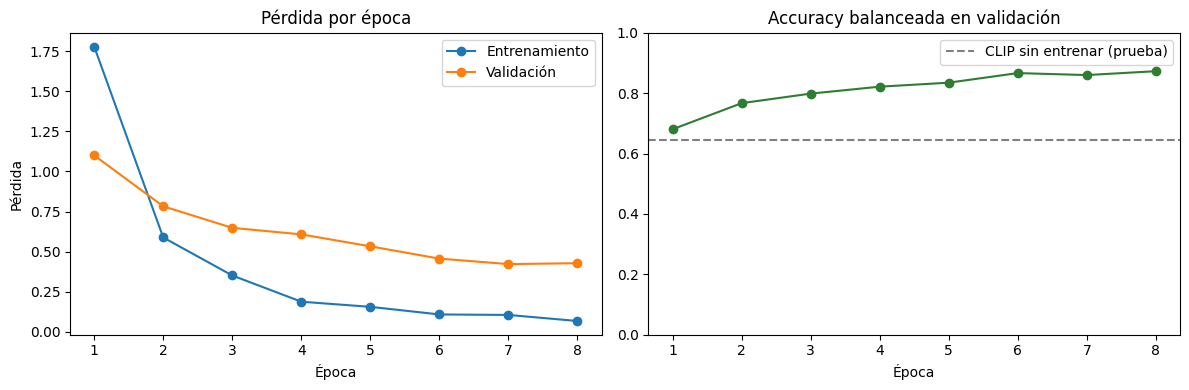

In [11]:
epocas = range(1, EPOCAS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epocas, historial["perdida_train"], "o-", label="Entrenamiento")   # curva de pérdida en train
ax[0].plot(epocas, historial["perdida_val"], "o-", label="Validación")        # curva de pérdida en val
ax[0].set_title("Pérdida por época"); ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida"); ax[0].legend()

ax[1].plot(epocas, historial["bal_val"], "o-", color="#2e7d32")               # accuracy balanceada en val
ax[1].axhline(RESULTADOS["CLIP (sin entrenar)"]["accuracy_balanceada"], ls="--", color="gray",
              label="CLIP sin entrenar (prueba)")                             # referencia: la línea base
ax[1].set_title("Accuracy balanceada en validación"); ax[1].set_xlabel("Época")
ax[1].set_ylim(0, 1); ax[1].legend()

plt.tight_layout(); plt.show()

**Curvas de aprendizaje:** las dos pérdidas bajan (entrenamiento de 1,78 a 0,07; validación de 1,10 a 0,43) y la accuracy balanceada en validación sube de 68,1 % a **87,3 %** (época 8, la versión guardada), siempre por sobre CLIP (línea gris). Desde la época 6 la mejora es mínima: el modelo se estabilizó.

**¿Hay overfitting?** La pérdida de entrenamiento queda más baja que la de validación, pero la de validación no sube: no hay overfitting dañino. Además, se guarda la mejor época según validación y el aumento de datos ayuda a contenerlo.


### 4.4 Evaluación en el conjunto de prueba
Cargamos la mejor versión del modelo (según validación) y lo evaluamos **una sola vez** en las **mismas 379 imágenes de prueba** que usamos con CLIP, con las mismas métricas. También guardamos la **confianza** de cada predicción (probabilidades obtenidas con *softmax*), que usará la app.

CLIP (sin entrenar)       · accuracy 60.2% · accuracy balanceada 64.4%
EfficientNet-B0 (timm)    · accuracy 85.0% · accuracy balanceada 84.7%

               precision    recall  f1-score   support

   cardboard       0.97      0.92      0.94        61
       glass       0.85      0.76      0.81        76
       metal       0.68      0.95      0.79        61
       paper       0.95      0.89      0.92        89
     plastic       0.96      0.76      0.85        72
       trash       0.57      0.80      0.67        20

    accuracy                           0.85       379
   macro avg       0.83      0.85      0.83       379
weighted avg       0.87      0.85      0.85       379



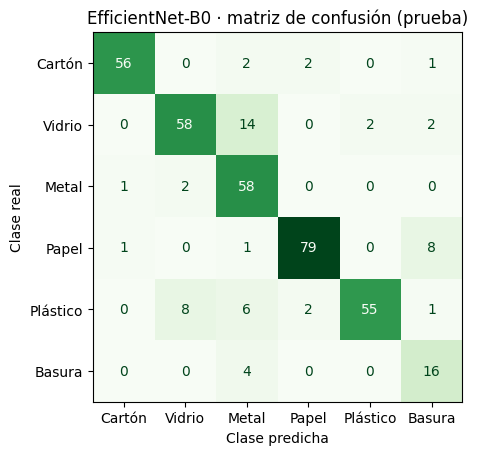

In [12]:
modelo.load_state_dict(torch.load("mejor_efficientnet.pt"))   # Recupera el mejor modelo guardado durante el entrenamiento (época 8)
modelo.eval()

reales_idx, preds_idx, probs_eff = [], [], []
with torch.no_grad():
    for x, y in dl_test:                                       # las 379 fotos de prueba, en el mismo orden que CLIP
        salida = modelo(x.to(DISPOSITIVO))
        probs_eff += torch.softmax(salida, dim=1).cpu().tolist()   # Convierte los 6 puntajes en probabilidades
        preds_idx += salida.argmax(1).cpu().tolist()           # clase con mayor probabilidad
        reales_idx += y.tolist()

reales_eff = [NOMBRES[i] for i in reales_idx]                  # números → nombres de clase
preds_eff  = [NOMBRES[i] for i in preds_idx]

RESULTADOS["EfficientNet-B0 (timm)"] = {
    "accuracy": accuracy_score(reales_eff, preds_eff),
    "accuracy_balanceada": balanced_accuracy_score(reales_eff, preds_eff),
}
for nombre, r in RESULTADOS.items():                           # compara con CLIP
    print(f"{nombre:25s} · accuracy {r['accuracy']:.1%} · accuracy balanceada {r['accuracy_balanceada']:.1%}")

print("\n", classification_report(reales_eff, preds_eff, labels=NOMBRES, digits=2))

# matriz de confusión: filas = clase real, columnas = clase predicha
mc = confusion_matrix(reales_eff, preds_eff, labels=NOMBRES) #Tabla que muestra qué clase se confunde con cuál
ConfusionMatrixDisplay(mc, display_labels=[ES[n] for n in NOMBRES]).plot(cmap="Greens", colorbar=False)
plt.title("EfficientNet-B0 · matriz de confusión (prueba)")
plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.show()

**Resultado en prueba (379 imágenes):** EfficientNet-B0 obtiene **85,0 % de accuracy** y **84,7 % de accuracy balanceada**, frente a 60,2 % y 64,4 % de CLIP sin entrenar: **+24,8 y +20,3 puntos** con las mismas imágenes y métricas. Esto justifica entrenar un modelo propio con transfer learning.

**Principales confusiones (matriz de confusión):**
- **Vidrio → metal (14 de 76):** la confusión más frecuente, probablemente por los brillos y reflejos que comparten ambos materiales.
- **Plástico → vidrio (8 de 72)** y **plástico → metal (6 de 72):** envases transparentes o brillantes.
- **Papel → basura (8 de 89).**

**Error más costoso — basura enviada a reciclaje:** 4 de las 20 imágenes de `trash` (20 %) se clasificaron como metal; esto contaminaría el lote de reciclaje. La clase alcanza un **recall de 0,80**, apoyado por la pérdida ponderada y el aumento de datos (con solo 20 imágenes de prueba, cada error equivale a 5 puntos).

**Error inverso — material reciclable enviado a la basura:** 12 imágenes reciclables (8 de ellas de papel) se clasificaron como basura (precision de `trash` 0,57). No contamina, pero se pierde material reciclable.

**Implicancia para la app:** como el modelo se equivoca en ~15 % de los casos y algunos errores son costosos, la app debe mostrar la confianza y pedir **revisión humana cuando sea baja**.

## 5. Tercer enfoque: YOLO-cls (Ultralytics)
YOLO es conocido por detectar objetos, pero su versión `-cls` clasifica imágenes completas. Su versión *nano* es muy liviana (~3 MB) y está pensada para funcionar rápido en producción. Lo comparamos para responder si un modelo aún más liviano es suficiente o si EfficientNet-B0 sigue siendo la mejor opción.

YOLO lee las imágenes desde carpetas (`train/`, `val/` y `test/`, con una subcarpeta por clase), por lo que guardamos las imágenes **respetando exactamente la misma división** usada con los otros modelos.

In [13]:
!pip install -q ultralytics                                   # instala la librería de YOLO
from ultralytics import YOLO

CARPETA_YOLO = "datos_yolo"
for parte, indices_parte in [("train", idx_train), ("val", idx_val), ("test", idx_test)]: #Recorre los tres conjuntos usando tus mismos índices de la división
    for i in indices_parte:                                   # recorre las fotos de cada conjunto
        foto = ds[int(i)]
        carpeta = f"{CARPETA_YOLO}/{parte}/{NOMBRES[foto['label']]}"   # ej: datos_yolo/train/glass
        os.makedirs(carpeta, exist_ok=True)                   # crea la carpeta
        foto["image"].convert("RGB").save(f"{carpeta}/{int(i):05d}.jpg")   # guarda la foto con su número

for parte in ["train", "val", "test"]:                        # comprueba cuántas fotos quedaron
    total = sum(len(os.listdir(f"{CARPETA_YOLO}/{parte}/{c}")) for c in NOMBRES)
    print(f"{parte:5s}: {total} imágenes")

train: 1766 imágenes
val  : 379 imágenes
test : 379 imágenes


### 5.1 Entrenamiento de YOLO-cls
Ultralytics entrena con la carpeta `train/`, revisa con `val/` al final de cada época y guarda automáticamente la mejor versión (`best.pt`). Aplica su propio aumento de datos, pero **no usa pesos por clase** (a diferencia de nuestro EfficientNet). Para comparar de forma justa usamos el mismo tamaño de imagen (224 px) y la misma semilla; entrenamos 10 épocas.

In [14]:
yolo = YOLO("yolo26n-cls.pt")          # YOLO nano de clasificación, preentrenado

yolo.train(data=CARPETA_YOLO,          # carpeta con train/ y val/ (una subcarpeta por clase)
           epochs=10,                  # número de épocas
           imgsz=TAM,                  # mismo tamaño de imagen que EfficientNet (224 px)
           seed=SEMILLA,               # misma semilla, para que sea reproducible
           plots=False)                # sin gráficos extra, para que la salida sea más corta

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datos_yolo, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, over

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x785813db73e0>
curves: []
curves_results: []
fitness: 0.9670184552669525
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.934036910533905, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9670184552669525}
save_dir: PosixPath('/content/runs/classify/train-2')
speed: {'preprocess': 0.07409523219048472, 'inference': 2.0084922321927183, 'loss': 0.005929773077285802, 'postprocess': 0.0006334881320820585}
top1: 0.934036910533905
top5: 1.0

**Resultado del entrenamiento:** en 10 épocas (~4 minutos), la accuracy en validación (`top1_acc`) sube hasta **93,4 %**, y se guarda la mejor época (`best.pt`). El modelo tiene solo **1,5 millones de parámetros** y pesa **3,2 MB**, con ~2 ms por imagen. Este valor es en validación y es accuracy normal (no balanceada), por lo que la comparación justa con los otros modelos se hace en prueba.

### 5.2 Evaluación en prueba

CLIP (sin entrenar)          · accuracy 60.2% · accuracy balanceada 64.4%
EfficientNet-B0 (timm)       · accuracy 85.0% · accuracy balanceada 84.7%
YOLO-cls nano (Ultralytics)  · accuracy 88.1% · accuracy balanceada 86.5%

               precision    recall  f1-score   support

   cardboard       0.90      0.92      0.91        61
       glass       0.86      0.88      0.87        76
       metal       0.85      0.90      0.87        61
       paper       0.89      0.92      0.91        89
     plastic       0.94      0.82      0.87        72
       trash       0.79      0.75      0.77        20

    accuracy                           0.88       379
   macro avg       0.87      0.87      0.87       379
weighted avg       0.88      0.88      0.88       379



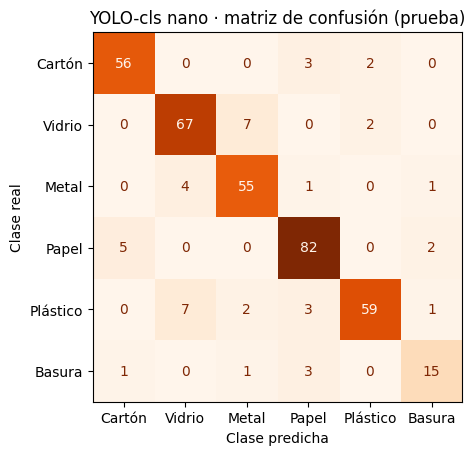

In [15]:
reales_yolo, preds_yolo = [], []
for i in idx_test:                                            # las mismas 379 fotos de prueba, en el mismo orden
    clase_real = NOMBRES[ds[int(i)]["label"]]
    ruta = f"{CARPETA_YOLO}/test/{clase_real}/{int(i):05d}.jpg"   # dónde guardamos esa foto
    r = yolo(ruta, verbose=False)[0]                          # YOLO clasifica la foto
    preds_yolo.append(r.names[r.probs.top1])                  # clase con mayor probabilidad
    reales_yolo.append(clase_real)

RESULTADOS["YOLO-cls nano (Ultralytics)"] = {
    "accuracy": accuracy_score(reales_yolo, preds_yolo),
    "accuracy_balanceada": balanced_accuracy_score(reales_yolo, preds_yolo),
}
for nombre, r in RESULTADOS.items():                          # tabla con los 3 enfoques
    print(f"{nombre:28s} · accuracy {r['accuracy']:.1%} · accuracy balanceada {r['accuracy_balanceada']:.1%}")

print("\n", classification_report(reales_yolo, preds_yolo, labels=NOMBRES, digits=2))

mc_yolo = confusion_matrix(reales_yolo, preds_yolo, labels=NOMBRES)
ConfusionMatrixDisplay(mc_yolo, display_labels=[ES[n] for n in NOMBRES]).plot(cmap="Oranges", colorbar=False)
plt.title("YOLO-cls nano · matriz de confusión (prueba)")
plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.show()

**Resultado en prueba (379 imágenes):** YOLO-cls nano obtiene **88,1 % de accuracy** y **86,5 % de accuracy balanceada**, el mejor resultado de los tres enfoques (334 aciertos de 379).

**Principales confusiones:** vidrio → metal (7 de 76) y plástico → vidrio (7 de 72), por brillos y transparencias; y papel → cartón (5 de 89), materiales de apariencia similar. La confusión vidrio → metal baja de 14 a 7 imágenes respecto a EfficientNet-B0.

**Error más costoso — basura enviada a reciclaje:** 5 de las 20 imágenes de `trash` (recall 0,75) se clasificaron como reciclables (3 como papel, 1 como cartón y 1 como metal).

**Error inverso — material reciclable enviado a la basura:** solo 4 imágenes (precision de `trash` 0,79), frente a 12 de EfficientNet-B0.

## 6. Comparación y elección del modelo
Los tres enfoques se evaluaron con las **mismas 379 imágenes de prueba** y las mismas métricas:

| Enfoque | Accuracy | Acc. balanceada | Basura → reciclaje | Reciclable → basura | Tamaño |
|---|---|---|---|---|---|
| CLIP (sin entrenar) | 60,2 % | 64,4 % | 3 de 20 | muy alto (precision `trash` 0,18) | ~605 MB |
| EfficientNet-B0 | 85,0 % | 84,7 % | 4 de 20 | 12 | ~16 MB |
| **YOLO-cls nano** | **88,1 %** | **86,5 %** | 5 de 20 | **4** | **3,2 MB** |

**Elegimos YOLO-cls nano** porque:
1. Tiene la mejor accuracy y accuracy balanceada con las mismas imágenes.
2. Envía 3 veces menos material reciclable a la basura que EfficientNet (4 vs. 12).
3. Es 5 veces más liviano (3,2 MB): cabe en GitHub y responde rápido en Streamlit Cloud, sin GPU.

**Costo de la elección:** en el error más costoso tiene 1 imagen más que EfficientNet (5 vs. 4 de 20), una diferencia no concluyente con solo 20 imágenes de basura. Este riesgo se aborda con el umbral de confianza para revisión humana (sección 9).

## 7. Prueba externa
Evaluamos el modelo elegido (YOLO-cls nano) con **fotos propias** de residuos chilenos, tomadas con iPhone en fondos y luces reales. El modelo **nunca vio estas imágenes**: sirven para comprobar si funciona fuera de las condiciones controladas de TrashNet (cartulina blanca, una sola fuente).

Las fotos están en Google Drive (`mis_fotos/`, una carpeta por clase). Se convierten de HEIC a JPG y se enderezan según la orientación guardada por el teléfono, sin modificar los originales.

In [16]:
from google.colab import drive
drive.mount("/content/drive")                                   # pide permiso para leer tu Google Drive

!pip install -q pillow-heif                                     # permite leer fotos HEIC del iPhone
from pillow_heif import register_heif_opener
register_heif_opener()
from PIL import Image, ImageOps

CARPETA_PROPIAS = "/content/drive/MyDrive/mis_fotos"            # tu carpeta en Drive
CARPETA_JPG = "propias_jpg"                                     # copia en JPG dentro de Colab
EXTENSIONES = (".jpg", ".jpeg", ".png", ".heic", ".heif", ".webp")

propias = []                                                    # lista de (ruta del JPG, clase real)
for clase in NOMBRES:
    os.makedirs(f"{CARPETA_JPG}/{clase}", exist_ok=True)
    archivos = sorted(a for a in os.listdir(f"{CARPETA_PROPIAS}/{clase}") if a.lower().endswith(EXTENSIONES))
    for n, archivo in enumerate(archivos):
        foto = Image.open(f"{CARPETA_PROPIAS}/{clase}/{archivo}")
        foto = ImageOps.exif_transpose(foto).convert("RGB")     # endereza la foto y la pasa a RGB
        ruta = f"{CARPETA_JPG}/{clase}/{clase}_{n:02d}.jpg"
        foto.save(ruta)                                         # guarda la copia en JPG
        propias.append((ruta, clase))
    print(f"{clase:10s}: {len(archivos)} fotos")
print("Total de fotos propias:", len(propias))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cardboard : 11 fotos
glass     : 8 fotos
metal     : 8 fotos
paper     : 10 fotos
plastic   : 11 fotos
trash     : 12 fotos
Total de fotos propias: 60


### 7.1 Evaluar YOLO con fotos propias

                        Accuracy  Acc. balanceada
TrashNet (prueba)          88.1%            86.5%
Fotos propias              26.7%            26.0%
Basura enviada a reciclaje: 11 de 12

               precision    recall  f1-score   support

   cardboard       0.25      0.64      0.36        11
       glass       0.00      0.00      0.00         8
       metal       0.29      0.25      0.27         8
       paper       0.23      0.50      0.31        10
     plastic       1.00      0.09      0.17        11
       trash       0.50      0.08      0.14        12

    accuracy                           0.27        60
   macro avg       0.38      0.26      0.21        60
weighted avg       0.41      0.27      0.21        60



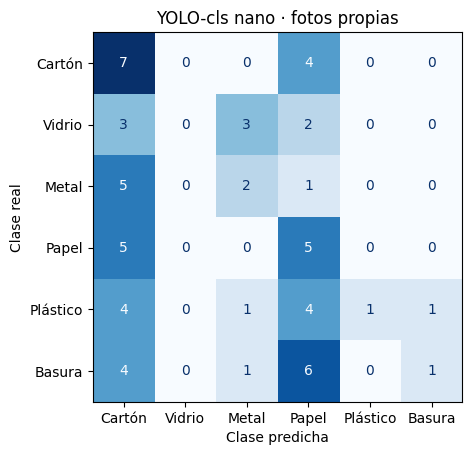

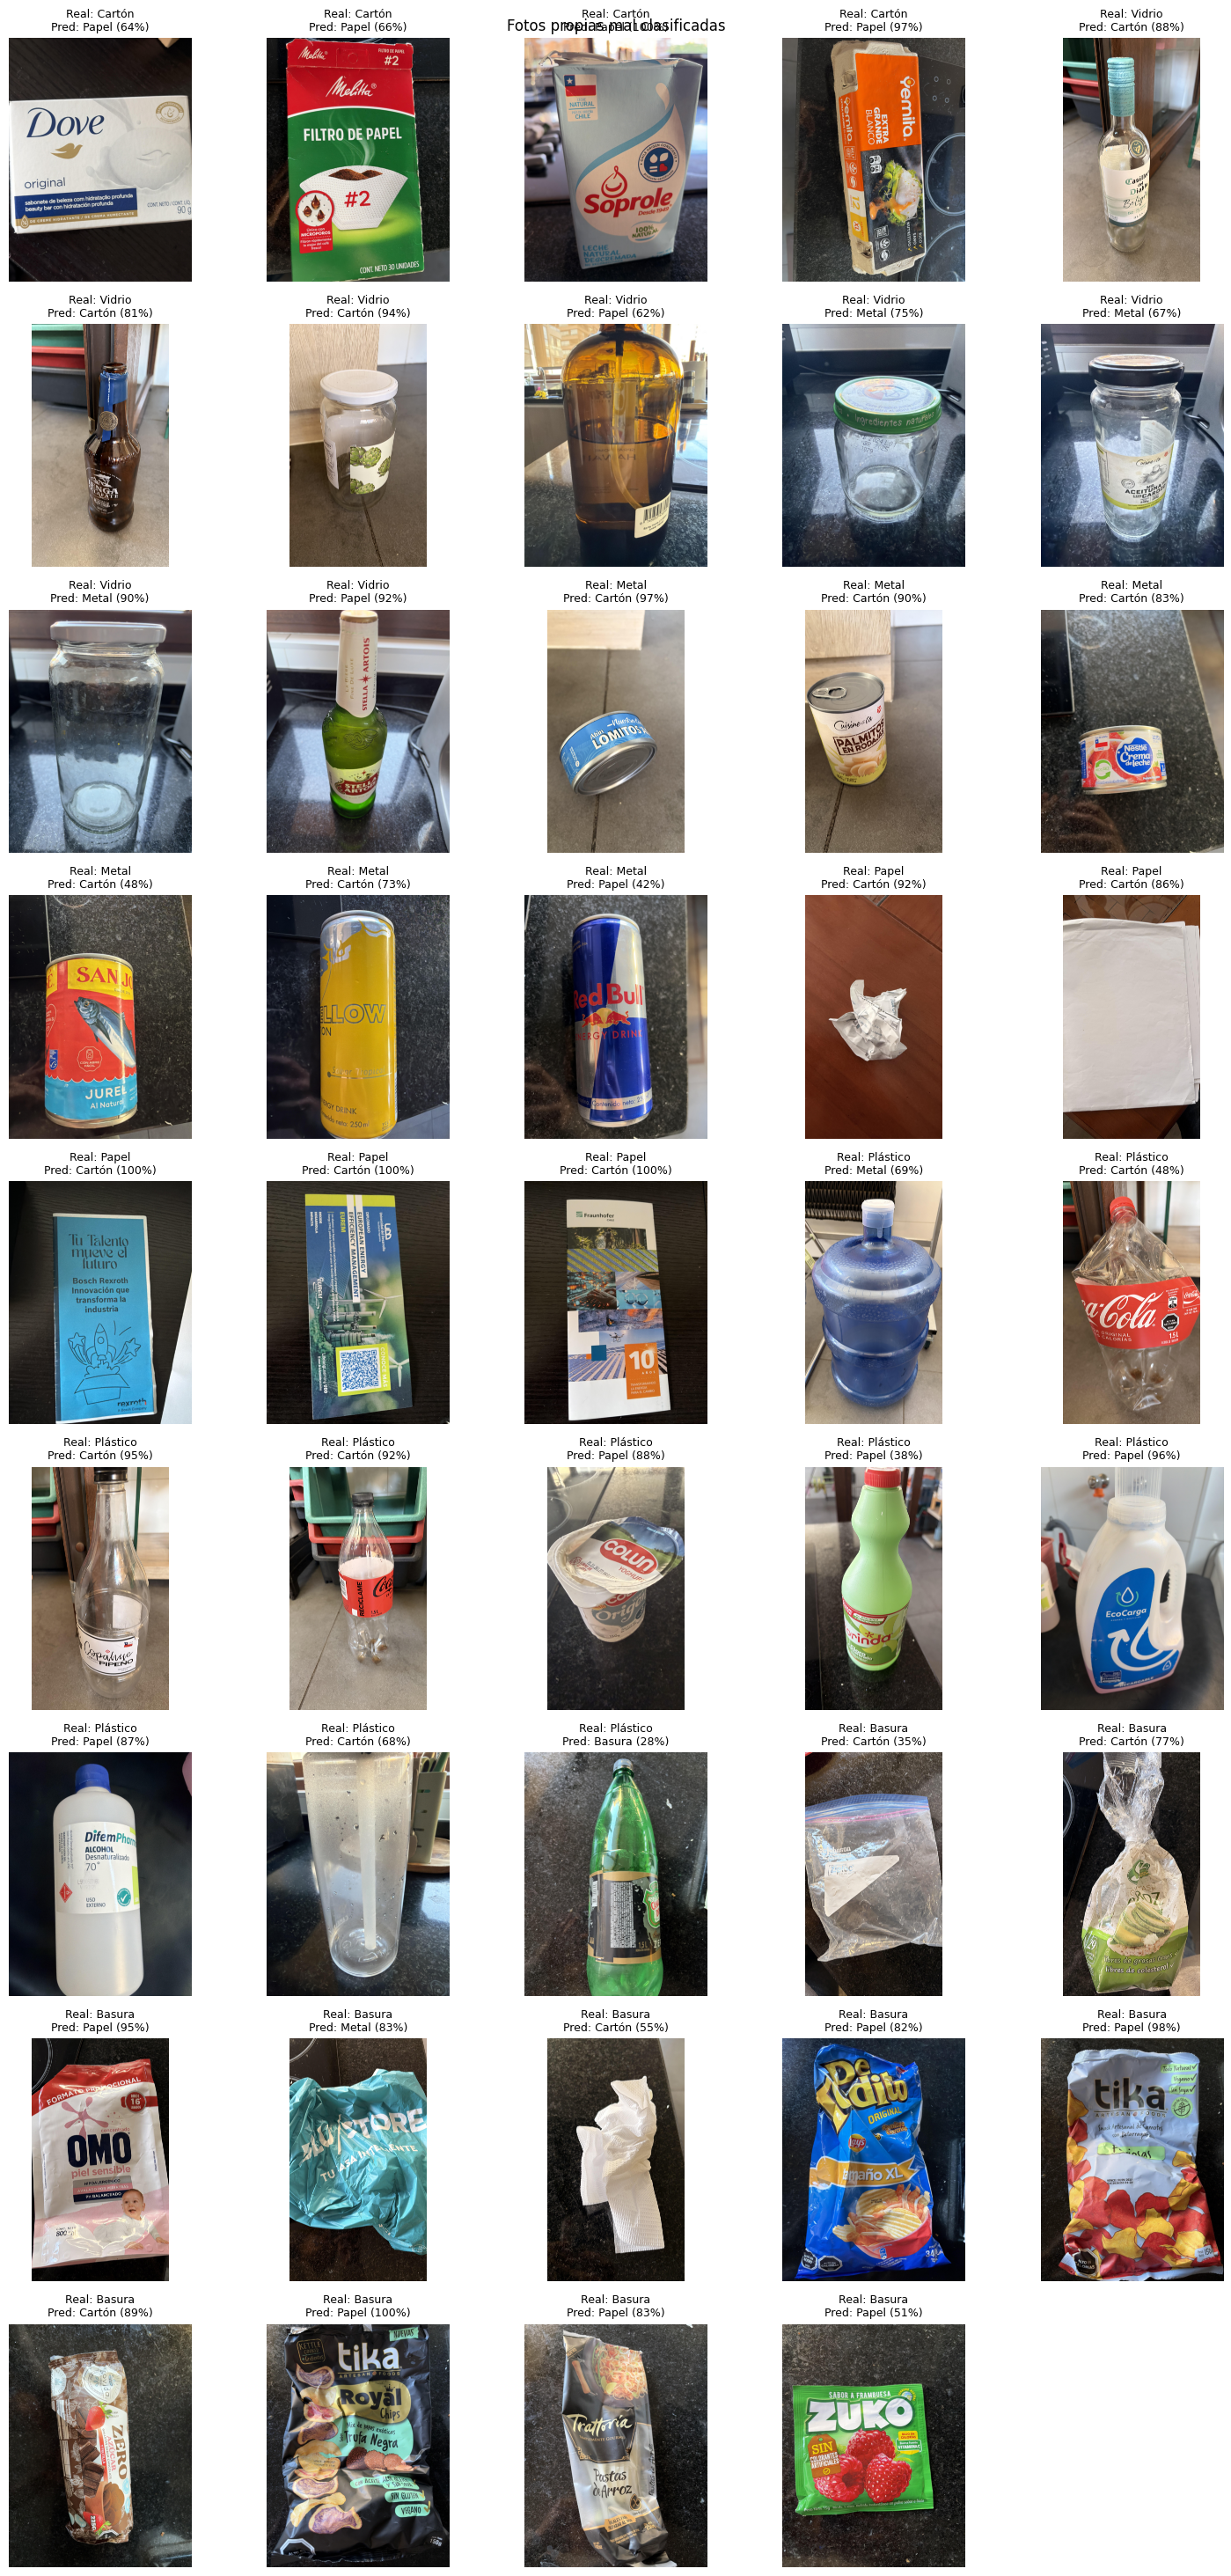

In [17]:
reales_p, preds_p, confs_p = [], [], []
for ruta, clase_real in propias:                                # recorre tus 60 fotos
    r = yolo(ruta, verbose=False)[0]
    reales_p.append(clase_real)
    preds_p.append(r.names[r.probs.top1])
    confs_p.append(float(r.probs.top1conf))
reales_p, preds_p, confs_p = np.array(reales_p), np.array(preds_p), np.array(confs_p)

acc_p = accuracy_score(reales_p, preds_p)
bal_p = balanced_accuracy_score(reales_p, preds_p)
yolo_test = RESULTADOS["YOLO-cls nano (Ultralytics)"]
print(f"{'':22s} {'Accuracy':>9s} {'Acc. balanceada':>16s}")
print(f"{'TrashNet (prueba)':22s} {yolo_test['accuracy']:9.1%} {yolo_test['accuracy_balanceada']:16.1%}")
print(f"{'Fotos propias':22s} {acc_p:9.1%} {bal_p:16.1%}")
print("Basura enviada a reciclaje:", ((reales_p == "trash") & (preds_p != "trash")).sum(),
      "de", (reales_p == "trash").sum())

print("\n", classification_report(reales_p, preds_p, labels=NOMBRES, digits=2, zero_division=0))

mc_p = confusion_matrix(reales_p, preds_p, labels=NOMBRES)
ConfusionMatrixDisplay(mc_p, display_labels=[ES[n] for n in NOMBRES]).plot(cmap="Blues", colorbar=False)
plt.title("YOLO-cls nano · fotos propias"); plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.show()

# muestra las fotos donde el modelo se equivocó
errores = [k for k in range(len(propias)) if reales_p[k] != preds_p[k]]
if errores:
    columnas = 5
    filas = int(np.ceil(len(errores) / columnas))
    plt.figure(figsize=(3 * columnas, 3.3 * filas))
    for n, k in enumerate(errores):
        plt.subplot(filas, columnas, n + 1)
        plt.imshow(Image.open(propias[k][0])); plt.axis("off")
        plt.title(f"Real: {ES[reales_p[k]]}\nPred: {ES[preds_p[k]]} ({confs_p[k]:.0%})", fontsize=9)
    plt.suptitle("Fotos propias mal clasificadas"); plt.tight_layout(); plt.show()

### 7.2 Los tres enfoques con fotos propias

In [18]:
preds_eff_p, preds_clip_p = [], []
for ruta, _ in propias:
    foto = Image.open(ruta).convert("RGB")
    with torch.no_grad():                                        # EfficientNet (la mejor época sigue cargada)
        x = tf_eval(foto).unsqueeze(0).to(DISPOSITIVO)
        preds_eff_p.append(NOMBRES[modelo(x).argmax(1).item()])
    respuesta = clip(foto, candidate_labels=list(TEXTOS.values()))   # CLIP sin entrenar
    preds_clip_p.append(A_CLASE[respuesta[0]["label"]])

print(f"{'Fotos propias':28s} {'Accuracy':>9s} {'Acc. balanceada':>16s}")
for nombre, preds in [("CLIP (sin entrenar)", preds_clip_p),
                      ("EfficientNet-B0 (timm)", preds_eff_p),
                      ("YOLO-cls nano (Ultralytics)", preds_p)]:
    print(f"{nombre:28s} {accuracy_score(reales_p, preds):9.1%} {balanced_accuracy_score(reales_p, preds):16.1%}")

Fotos propias                 Accuracy  Acc. balanceada
CLIP (sin entrenar)              68.3%            68.2%
EfficientNet-B0 (timm)           38.3%            39.0%
YOLO-cls nano (Ultralytics)      26.7%            26.0%


**Resultado de la prueba externa:** con las 60 fotos propias, YOLO cae de 86,5 % a **26,0 %** de accuracy balanceada y envía a reciclaje 11 de las 12 fotos de basura. EfficientNet también cae (39,0 %). En cambio, **CLIP se mantiene en 68,2 %**, porque no se entrenó con TrashNet.

**Hallazgo (cambio de dominio):** los modelos entrenados aprendieron las condiciones de TrashNet (un objeto sobre cartulina blanca, con encuadre parecido) más que el material. Las fotos mal clasificadas lo muestran: fondos con textura, objetos pequeños y luz distinta.

**¿Por qué no cambiar a CLIP?** En la prueba de TrashNet acierta solo el 60 % y envía mucho material reciclable a la basura (precision `trash` 0,18); además pesa ~605 MB, demasiado para una app gratuita. Con solo 60 fotos propias, su ventaja es indicativa. **Decisión:** mantener YOLO e intentar hacerlo más robusto (sección 8).

## 8. Mejora: YOLO v2 con aumento de datos más fuerte
Para reducir el cambio de dominio detectado en la sección 7, reentrenamos el **mismo YOLO-cls nano** con un **aumento de datos más fuerte**: más recortes y acercamientos al azar de cada foto de entrenamiento. Así el modelo ve los objetos encuadrados de muchas formas y con menos cartulina blanca alrededor, y aprende a fijarse en el objeto y no en lo que lo rodea. También entrenamos más épocas (15), porque con más variación el modelo necesita más tiempo para aprender.

Validación y prueba se mantienen originales, para comparar de forma justa con el YOLO anterior.

> **Nota:** como usamos las fotos propias para detectar el problema y comparar v1 y v2, sus resultados son **indicativos**, no una prueba independiente. La decisión también se apoya en validación y en la prueba de TrashNet.

In [19]:
yolo_v2 = YOLO("yolo26n-cls.pt")          # parte de nuevo desde el YOLO preentrenado (mismo punto de partida)

yolo_v2.train(data=CARPETA_YOLO,          # mismas carpetas train/ y val/
              epochs=15,                  # más épocas
              imgsz=TAM,                  # mismo tamaño: 224 px
              seed=SEMILLA,               # misma semilla
              scale=0.8,                  # aumento más fuerte: recortes y acercamientos al azar
              name="yolo_v2",             # se guarda aparte, sin borrar el YOLO original
              plots=False)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datos_yolo, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_v2-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x785737ff25f0>
curves: []
curves_results: []
fitness: 0.9762533009052277
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9525066018104553, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9762533009052277}
save_dir: PosixPath('/content/runs/classify/yolo_v2-2')
speed: {'preprocess': 0.06750542743823866, 'inference': 0.587129232199028, 'loss': 0.005864321898202422, 'postprocess': 0.0005825857485882265}
top1: 0.9525066018104553
top5: 1.0

### 8.1 Comparación: YOLO v1 vs. YOLO v2
Evaluamos ambas versiones en la prueba de TrashNet (379 imágenes) y en las fotos propias (60 imágenes), con las mismas métricas y el error más costoso.

           Prueba      Accuracy  Acc. bal.  Basura→reciclaje
YOLO v1    TrashNet       88.1%      86.5%           5 de 20
YOLO v2    TrashNet       91.6%      91.1%           2 de 20
YOLO v1    Propias        26.7%      26.0%          11 de 12
YOLO v2    Propias        35.0%      33.1%           8 de 12


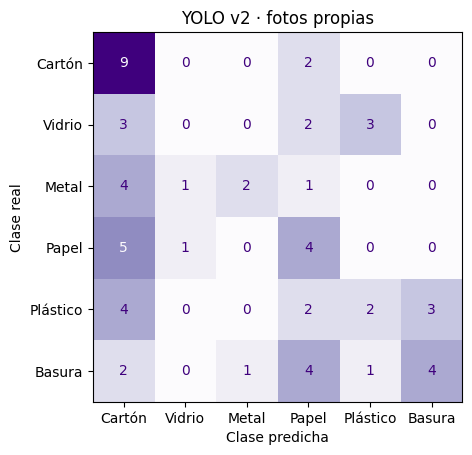

In [20]:
def clasificar(modelo_yolo, rutas):
    """Clasifica una lista de fotos con un modelo YOLO y devuelve las clases predichas y la confianza."""
    preds, confs = [], []
    for ruta in rutas:
        r = modelo_yolo(ruta, verbose=False)[0]
        preds.append(r.names[r.probs.top1])
        confs.append(float(r.probs.top1conf))
    return np.array(preds), np.array(confs)

# rutas y clases reales de las dos pruebas
rutas_test = [f"{CARPETA_YOLO}/test/{NOMBRES[ds[int(i)]['label']]}/{int(i):05d}.jpg" for i in idx_test]
reales_test = np.array([NOMBRES[ds[int(i)]["label"]] for i in idx_test])
rutas_prop = [ruta for ruta, _ in propias]

p_test_v2, c_test_v2 = clasificar(yolo_v2, rutas_test)          # v2 en la prueba de TrashNet
p_prop_v2, c_prop_v2 = clasificar(yolo_v2, rutas_prop)          # v2 en tus fotos

RESULTADOS["YOLO-cls nano v2 (aumento fuerte)"] = {
    "accuracy": accuracy_score(reales_test, p_test_v2),
    "accuracy_balanceada": balanced_accuracy_score(reales_test, p_test_v2),
}

def basura_a_reciclaje(reales, preds):                          # error más costoso
    reales, preds = np.array(reales), np.array(preds)
    return f"{((reales == 'trash') & (preds != 'trash')).sum()} de {(reales == 'trash').sum()}"

print(f"{'':10s} {'Prueba':10s} {'Accuracy':>9s} {'Acc. bal.':>10s} {'Basura→reciclaje':>17s}")
for version, prueba, reales_x, preds_x in [
        ("YOLO v1", "TrashNet", reales_yolo, preds_yolo),
        ("YOLO v2", "TrashNet", reales_test, p_test_v2),
        ("YOLO v1", "Propias",  reales_p,    preds_p),
        ("YOLO v2", "Propias",  reales_p,    p_prop_v2)]:
    print(f"{version:10s} {prueba:10s} {accuracy_score(reales_x, preds_x):9.1%} "
          f"{balanced_accuracy_score(reales_x, preds_x):10.1%} {basura_a_reciclaje(reales_x, preds_x):>17s}")

mc_v2 = confusion_matrix(reales_p, p_prop_v2, labels=NOMBRES)   # matriz de v2 con tus fotos
ConfusionMatrixDisplay(mc_v2, display_labels=[ES[n] for n in NOMBRES]).plot(cmap="Purples", colorbar=False)
plt.title("YOLO v2 · fotos propias"); plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.show()

**Resultado:** YOLO v2 mejora en todas las pruebas. En **validación** sube de 93,4 % a 95,3 %. En la **prueba de TrashNet** pasa de 86,5 % a **91,1 %** de accuracy balanceada, y la basura enviada a reciclaje baja de 5 a **2 de 20**. Con **fotos propias** mejora de 26,0 % a 33,1 % (basura → reciclaje de 11 a 8 de 12), pero sigue lejos de un uso real: no reconoce ningún vidrio (0 de 8).

**Decisión:** YOLO v2 es el **modelo final** de la app. Como la mejora con fotos reales es parcial, la app guiará al usuario a fotografiar un solo objeto sobre fondo liso y claro, y se declara como limitación. Mejora futura: reentrenar con fotos chilenas en fondos reales.

## 9. Umbral de confianza para revisión humana
La app pide revisión humana cuando la confianza del modelo es baja. Para definir qué es "baja", probamos distintos umbrales con YOLO v2 en el conjunto de **validación** (la prueba se reserva para verificar) y medimos:
- **Cobertura:** % de imágenes que la app clasifica sin pedir revisión.
- **Acierto en las clasificadas:** qué tan correcto es el modelo cuando responde solo.
- **Basura → reciclaje sin aviso:** el error más costoso que pasa sin advertencia.

In [21]:
rutas_val = [f"{CARPETA_YOLO}/val/{NOMBRES[ds[int(i)]['label']]}/{int(i):05d}.jpg" for i in idx_val]
reales_val = np.array([NOMBRES[ds[int(i)]["label"]] for i in idx_val])
p_val_v2, c_val_v2 = clasificar(yolo_v2, rutas_val)                 # YOLO v2 en VALIDACIÓN

print(f"{'Umbral':>6s} {'Cobertura':>10s} {'Acc. clasificadas':>18s} {'Basura→reciclaje':>17s}")
for umbral in [0.50, 0.60, 0.70, 0.80, 0.90]:
    auto = c_val_v2 >= umbral                                        # fotos que respondería sin pedir revisión
    cobertura = auto.mean()                                          # % que responde solo
    acc_auto = (reales_val[auto] == p_val_v2[auto]).mean()           # acierto cuando responde solo
    costoso = ((reales_val == "trash") & (p_val_v2 != "trash") & auto).sum()   # basura a reciclaje sin aviso
    print(f"{umbral:6.0%} {cobertura:10.1%} {acc_auto:18.1%} {costoso:17d}")

Umbral  Cobertura  Acc. clasificadas  Basura→reciclaje
   50%      98.2%              96.5%                 0
   60%      95.5%              97.0%                 0
   70%      92.9%              97.2%                 0
   80%      89.2%              98.2%                 0
   90%      83.6%              99.1%                 0


**Elección:** con YOLO v2, ningún umbral deja pasar basura a reciclaje en validación, por lo que la elección depende del equilibrio entre acierto y revisiones. Se mantiene el **umbral de 60 %**: el acierto sube de 96,5 % a 97,0 % respecto a 50 %, pidiendo revisión solo en el 4,5 % de los casos; subir a 70 % casi no mejora el acierto (+0,2 puntos) y aumenta las revisiones.

In [22]:
UMBRAL = 0.60                                                       # umbral final

for nombre_prueba, reales_x, preds_x, confs_x in [
        ("Prueba TrashNet", reales_test, p_test_v2, c_test_v2),
        ("Fotos propias",   reales_p,    p_prop_v2, c_prop_v2)]:
    auto = confs_x >= UMBRAL
    sin_aviso = ((reales_x == "trash") & (preds_x != "trash") & auto).sum()
    total = ((reales_x == "trash") & (preds_x != "trash")).sum()
    print(f"{nombre_prueba}:")
    print(f" - responde solo en {auto.mean():.1%} · pide revisión en {1 - auto.mean():.1%}")
    print(f" - acierto cuando responde solo: {(reales_x[auto] == preds_x[auto]).mean():.1%}")
    print(f" - acierto en las que pide revisión: {(reales_x[~auto] == preds_x[~auto]).mean():.1%}")
    print(f" - basura → reciclaje: {total} en total, {sin_aviso} sin advertencia\n")

Prueba TrashNet:
 - responde solo en 95.8% · pide revisión en 4.2%
 - acierto cuando responde solo: 93.4%
 - acierto en las que pide revisión: 50.0%
 - basura → reciclaje: 2 en total, 1 sin advertencia

Fotos propias:
 - responde solo en 70.0% · pide revisión en 30.0%
 - acierto cuando responde solo: 38.1%
 - acierto en las que pide revisión: 27.8%
 - basura → reciclaje: 8 en total, 6 sin advertencia



**Verificación del umbral de 60 % con YOLO v2:**
- **Prueba de TrashNet:** la app responde sola en el 95,8 % de las imágenes, con **93,4 % de acierto**, y pide revisión en el 4,2 %. Solo 1 imagen de basura llega a reciclaje sin advertencia.
- **Fotos propias:** pide revisión en el **30 %** de los casos: el modelo v2 reconoce mejor cuándo duda. Sin embargo, 6 de 8 imágenes de basura mal clasificadas pasarían sin advertencia, por lo que con fotos reales el umbral **ayuda, pero no es suficiente**: la app debe guiar al usuario para tomar fotos con fondo liso y claro.

## 10. Exportación del modelo final

Guardamos en la carpeta `modelo/` los tres archivos que usa la app:
- `modelo_yolo.pt`: pesos de YOLO v2 (mejor época según validación).
- `clases.json`: nombres de las 6 clases en el orden del modelo.
- `metricas.json`: métricas en prueba, resultados con fotos propias, comparación de enfoques y umbral de 60 %.

Así la app muestra el desempeño real medido en prueba, sin escribir números a mano.

In [24]:
os.makedirs("modelo", exist_ok=True)                    # crea la carpeta "modelo/" (igual que en el repositorio)
shutil.copy(yolo_v2.trainer.best, "modelo/modelo_yolo.pt")   # copia el best.pt de este entrenamiento de v2

with open("modelo/clases.json", "w", encoding="utf-8") as f:
    json.dump(NOMBRES, f)

recall_v2 = recall_score(reales_test, p_test_v2, labels=NOMBRES, average=None)
metricas = {
    "modelo": "YOLO-cls nano v2 (Ultralytics, aumento de datos fuerte)",
    "accuracy": accuracy_score(reales_test, p_test_v2),
    "accuracy_balanceada": balanced_accuracy_score(reales_test, p_test_v2),
    "n_test": len(reales_test),
    "recall_por_clase": {c: float(v) for c, v in zip(NOMBRES, recall_v2)},
    "umbral_confianza": UMBRAL,
    "cobertura_test": float((c_test_v2 >= UMBRAL).mean()),
    "fotos_propias": {"n": len(reales_p),
                      "accuracy": accuracy_score(reales_p, p_prop_v2),
                      "accuracy_balanceada": balanced_accuracy_score(reales_p, p_prop_v2)},
    "comparacion": RESULTADOS,                                     # los 4 modelos en la prueba de TrashNet
}
with open("modelo/metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)

# comprobación: el archivo exportado funciona por sí solo
yolo_final = YOLO("modelo/modelo_yolo.pt")
r = yolo_final(rutas_test[0], verbose=False)[0]
print(f"Prueba del modelo exportado → real: {reales_test[0]} · predicho: {r.names[r.probs.top1]} "
      f"({float(r.probs.top1conf):.1%})")
print(f"Accuracy balanceada en prueba (guardada): {metricas['accuracy_balanceada']:.1%}")
for archivo in os.listdir("modelo"):
    print(f"{archivo:18s} {os.path.getsize(f'modelo/{archivo}') / 1e6:.2f} MB")

shutil.make_archive("modelo", "zip", "modelo")
files.download("modelo.zip")

Prueba del modelo exportado → real: metal · predicho: metal (99.7%)
Accuracy balanceada en prueba (guardada): 91.1%
metricas.json      0.00 MB
clases.json        0.00 MB
modelo_yolo.pt     3.20 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusión

### Resultados finales (prueba de TrashNet, 379 imágenes)
| Enfoque | Accuracy | Acc. balanceada | Basura → reciclaje |
|---|---|---|---|
| CLIP (sin entrenar) | 60,2 % | 64,4 % | 3 de 20 |
| EfficientNet-B0 | 85,0 % | 84,7 % | 4 de 20 |
| YOLO-cls nano v1 | 88,1 % | 86,5 % | 5 de 20 |
| **YOLO-cls nano v2 (modelo final)** | **91,6 %** | **91,1 %** | **2 de 20** |

Con el umbral de 60 %, la app responde sola en el 95,8 % de los casos con 93,4 % de acierto, y solo 1 imagen de basura llega a reciclaje sin advertencia.

### Qué hicimos y por qué
1. **Línea base (CLIP):** un modelo general sin entrenar acierta solo el 60 %, lo que justifica entrenar uno propio con *transfer learning*.
2. **Comparación de tres enfoques** con los mismos datos y métricas: elegimos **YOLO-cls nano** por tener el mejor desempeño, enviar menos reciclables a la basura y pesar solo 3,2 MB.
3. **Prueba externa con fotos propias:** reveló un **cambio de dominio**; el modelo había aprendido las condiciones de TrashNet (cartulina blanca) más que el material.
4. **Mejora (YOLO v2):** un aumento de datos más fuerte mejoró todas las pruebas y redujo el error más costoso de 5 a 2 de 20.
5. **Umbral de revisión humana (60 %):** protege al usuario en los casos en que el modelo duda.

### Aprendizajes
- **La accuracy sola engaña:** con clases desbalanceadas hay que mirar la accuracy balanceada, el recall por clase y el error más costoso.
- **Un buen resultado en prueba no garantiza un buen resultado en el mundo real:** probar con datos externos fue clave para descubrir la limitación.
- **El modelo aprende las condiciones de las fotos, no solo el objeto.**

### Riesgos y limitaciones
- Con fotos reales el modelo sigue siendo débil (33,1 % de accuracy balanceada con fotos propias; no reconoce vidrio), y el umbral no detecta todos los errores: 6 de 8 imágenes de basura mal clasificadas pasarían sin advertencia.
- Las fotos propias (60) son pocas y se usaron para comparar v1 y v2, por lo que su resultado es **indicativo**.
- La clase `trash` tiene solo 20 imágenes en prueba: cada error cambia su recall en 5 puntos.
- **Clasificador cerrado:** el modelo siempre elige uno de los 6 materiales, aunque la imagen no sea un residuo (al probar la app, un zapato se clasificó como metal con 97 % de confianza). El umbral no lo detecta porque el modelo está "seguro" de su error; la app lo advierte al usuario.

### Cómo lo aborda la app
La app mostrará la clase, la confianza y las probabilidades, pedirá revisión humana bajo el 60 %, **guiará al usuario a fotografiar un solo objeto sobre fondo liso y claro** y entregará una recomendación de Gemini con un *prompt* responsable. Es un **prototipo educativo**: ante la duda, se debe revisar el residuo o consultar las indicaciones del punto limpio.

### Mejoras futuras
- Reentrenar con **fotos chilenas en fondos y luces reales**, para reducir el cambio de dominio.
- Agregar más imágenes de `trash` y de envases ambiguos (Tetra Pak, bolsas, plásticos mixtos).
- Evaluar con un conjunto externo más grande e independiente.
- Agregar una clase `otro` con objetos que no son residuos, fotografiados en las mismas condiciones que TrashNet (fondo blanco), para que el modelo aprenda a responder "esto no es un residuo".